# TD1 — Temporal data contract and forecasting baselines — Core

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Learning contract

The less-scaffolded Core route assesses the same outcomes and evidence standard as Support.

In [2]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: D:\Documents\ESILV\A5\DIA\Machine learning\Advanced_Machine_Learning_ESILV_2026-2027_DVL_final
Primary path: locked local CPU; check the release evidence before using Colab


## 1 — Temporal contract and anti-leakage invariants

Load only public development data; record its hash and decision contract. Implement row/date/target/censoring invariants plus a failing negative test.

In [9]:
import hashlib, numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error
from shared.data import dataset_path
from shared.evaluation import smape
path=dataset_path('daily_demand_development.csv')
demand=pd.read_csv(path,parse_dates=['date'])
data_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
print(demand.shape,data_sha256[:16])

TARGET='demand_units'
CENSOR_COLS=['stockout_flag']
N_EXPECTED=1433

forecast_contract={
    'unit':'one product-level daily demand series (units per day)',
    'target':TARGET,
    'frequency':'D',
    'forecast_origin':'last day of the training block (day before the first validation date)',
    'horizon':28,
    'season':7,
    'known_at_prediction_time':['date','calendar position (weekday)'],   # adapt to what the data card says
    'not_known_at_prediction_time':['stockout_flag','future demand_units'],
    'censoring':'stockout_flag=1 marks CENSORED recorded sales (a lower bound), NOT latent unconstrained demand',
    'validation':'final 28 days of daily_demand_development.csv; protected final horizon never read',
    'metrics':['MAE','sMAPE'],
    'baselines':['historical_mean','last_value','seasonal_naive_lag7'],
    'data_sha256':data_sha256,
    'seeds':[11,23,37,51,71],
}

def assert_daily_contract(frame):
    assert 'date' in frame.columns and TARGET in frame.columns, 'colonnes manquantes'
    assert not frame['date'].duplicated().any(), 'dates dupliquées'
    assert frame['date'].is_monotonic_increasing, 'dates non triées'
    assert (frame['date'].diff().dropna()>pd.Timedelta(0)).all(), 'dates non strictement croissantes'
    full=pd.date_range(frame['date'].min(),frame['date'].max(),freq='D')
    assert len(full)==len(frame) and (frame['date'].values==full.values).all(), 'jours manquants'
    y=frame[TARGET].to_numpy(dtype=float)
    assert np.isfinite(y).all(), 'cible NaN ou infinie'
    assert (y>=0).all(), 'demande négative'
    for c in CENSOR_COLS:
        assert set(frame[c].dropna().unique())<={0,1}, f'{c} non binaire'
    return True

print('Données valides :',assert_daily_contract(demand))
assert len(demand)==N_EXPECTED, f'attendu {N_EXPECTED} lignes, obtenu {len(demand)}'

# Profil : manquants, zéros, censure, promotions, fêtes
print('Valeurs manquantes :',demand.isna().sum().to_dict())
print('Jours à demande nulle :',int((demand[TARGET]==0).sum()))
print('Jours censurés (stockout_flag=1) :',int(demand['stockout_flag'].sum()))
print('Jours promo / période de fêtes :',int(demand['promotion'].sum()),'/',int(demand['holiday_period'].sum()))

def must_fail(name,broken):
    try: assert_daily_contract(broken)
    except AssertionError as e: print(f'OK (échec attendu) {name}: {e}')
    else: raise RuntimeError(f'Le test négatif "{name}" n\'a PAS échoué !')

must_fail('mélange des dates', demand.sample(frac=1,random_state=11))
must_fail('jour supprimé', demand.drop(demand.index[50]))
must_fail('date dupliquée', pd.concat([demand,demand.iloc[[10]]]).sort_values('date'))
bad=demand.copy(); bad.loc[bad.index[5],TARGET]=np.nan; must_fail('NaN dans la cible', bad)
bad=demand.copy(); bad.loc[bad.index[5],TARGET]=-1; must_fail('demande négative', bad)
bad=demand.copy(); bad.loc[bad.index[5],'stockout_flag']=2; must_fail('drapeau non binaire', bad)

(1433, 5) b275d65b07f44795
Données valides : True
Valeurs manquantes : {'date': 0, 'demand_units': 0, 'promotion': 0, 'holiday_period': 0, 'stockout_flag': 0}
Jours à demande nulle : 0
Jours censurés (stockout_flag=1) : 32
Jours promo / période de fêtes : 126 / 42
OK (échec attendu) mélange des dates: dates non triées
OK (échec attendu) jour supprimé: jours manquants
OK (échec attendu) date dupliquée: dates dupliquées
OK (échec attendu) NaN dans la cible: cible NaN ou infinie
OK (échec attendu) demande négative: demande négative
OK (échec attendu) drapeau non binaire: stockout_flag non binaire


## 2 — Baselines and evidence

Freeze the final 28 public development days. Implement historical mean, last value, and lag-7 seasonal naive from earlier history only; compare MAE/sMAPE on aligned dates.

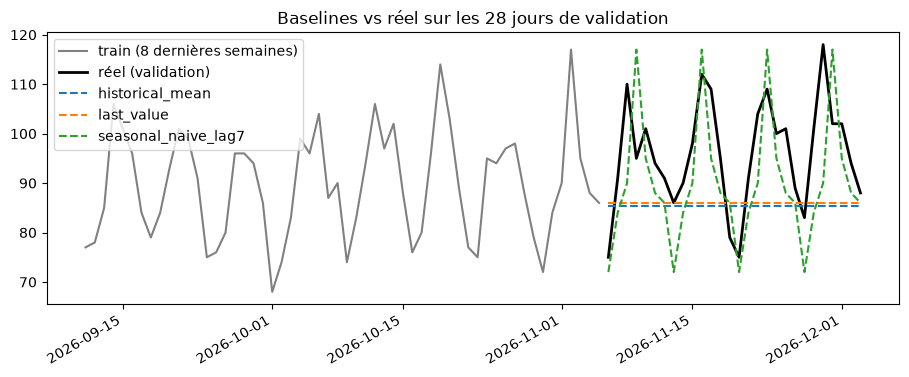

,baseline,MAE,sMAPE
0,seasonal_naive_lag7,9.607143,10.130650
1,last_value,12.107143,12.956200
2,historical_mean,12.557067,13.477491


In [12]:
import matplotlib.pyplot as plt

train=demand.iloc[:-28].copy(); validation=demand.iloc[-28:].copy(); assert train.date.max()<validation.date.min()

def baseline_forecasts(train_values,horizon=28,season=7):
    v=np.asarray(train_values,dtype=float)
    assert np.isfinite(v).all() and len(v)>=season, 'historique invalide'
    hist_mean=np.full(horizon,v.mean())
    last_value=np.full(horizon,v[-1])
    last_cycle=v[-season:]                       # la dernière semaine connue
    seasonal=np.array([last_cycle[h%season] for h in range(horizon)])
    out={'historical_mean':hist_mean,'last_value':last_value,'seasonal_naive_lag7':seasonal}
    for k,a in out.items():
        assert len(a)==horizon and np.isfinite(a).all(), k
    return out

y_true=validation[TARGET].to_numpy(dtype=float)
forecasts=baseline_forecasts(train[TARGET].to_numpy(),horizon=28,season=7)

rows=[]
for name,pred in forecasts.items():
    assert len(pred)==len(y_true)               # même longueur, mêmes dates
    rows.append({'baseline':name,
                 'MAE':mean_absolute_error(y_true,pred),
                 'sMAPE':smape(y_true,pred)})
scores=pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)

# Figure : réalité vs baselines sur les mêmes dates
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(train.date.iloc[-56:],train[TARGET].iloc[-56:],color='grey',label='train (8 dernières semaines)')
ax.plot(validation.date,y_true,color='black',lw=2,label='réel (validation)')
for name,pred in forecasts.items():
    ax.plot(validation.date,pred,ls='--',label=name)
ax.set_title('Baselines vs réel sur les 28 jours de validation'); ax.legend(); fig.autofmt_xdate()
plt.show()
scores

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [11]:
interpretation=(
 "On the final 28 public development days (2026-11-06 to 2026-12-03), seasonal-naive lag-7 has the lowest error "
 "(MAE=9.61, sMAPE=10.13%) versus 12.11/12.96% for last value and 12.56/13.48% for the historical mean, "
 "about 20% lower MAE than the best flat baseline. "
 "This supports a stable weekly cycle; it does not show that the ranking holds on other periods, since it rests on one 28-day block "
 "with no uncertainty interval. "
 "Failure period: late November (2026-11-28 to 11-30) and 2026-11-08/09. The five worst days carry about 38% of total absolute error. "
 "Three of them are promotion days (11-08, 11-28, 11-29) that were underforecast by 17 to 28 units because the last training week had no promotion, "
 "and the Monday peak of 117 from 2026-11-02 was copied onto later Mondays, overforecasting by 15 to 22 units. "
 "Operational limitation: lag-7 copies the last observed week and ignores the promotion calendar, "
 "so any anomaly in that week is replicated across the 28-day horizon, and stockout-flagged days (censored sales) would be measured against a lower bound of demand. "
 "Lag-7 is therefore the reference to beat on the same block and dates, and promotions are the first thing a later model should handle."
)
print(interpretation)

On the final 28 public development days (2026-11-06 to 2026-12-03), seasonal-naive lag-7 has the lowest error (MAE=9.61, sMAPE=10.13%) versus 12.11/12.96% for last value and 12.56/13.48% for the historical mean, about 20% lower MAE than the best flat baseline. This supports a stable weekly cycle; it does not show that the ranking holds on other periods, since it rests on one 28-day block with no uncertainty interval. Failure period: late November (2026-11-28 to 11-30) and 2026-11-08/09. The five worst days carry about 38% of total absolute error. Three of them are promotion days (11-08, 11-28, 11-29) that were underforecast by 17 to 28 units because the last training week had no promotion, and the Monday peak of 117 from 2026-11-02 was copied onto later Mondays, overforecasting by 15 to 22 units. Operational limitation: lag-7 copies the last observed week and ignores the promotion calendar, so any anomaly in that week is replicated across the 28-day horizon, and stockout-flagged days (

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.